# UJIAN AKHIR SEMESTER - PENGANTAR BIG DATA
### Analisa & Cleaning Dataset Penjualan (NIM Ganjil)

**Nama**: Agus Dwijayanto
**NIM**: 241011750001
**Kelas**: 03SIFE003
**Dataset**: `dataset_kasus_penjualan.csv`


## 0. Import Library yang Dibutuhkan

In [1]:
# Import semua library yang dibutuhkan untuk analisa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

import nltk
import string
from nltk.tokenize import word_tokenize
from collections import Counter

# Download resource nltk yang diperlukan (jalankan sekali saja)
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

from nltk.corpus import stopwords

# Atur tampilan plot
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

[nltk_data] Downloading package punkt to /Users/agus/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /Users/agus/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/agus/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 1. Import Dataset

In [4]:
# Membaca file dataset dengan Pandas
df = pd.read_csv('dataset_kasus_penjualan.csv')

# Menampilkan 10 baris pertama
df.head(10)

,id,nama,kategori,harga,jumlah,rating,tanggal_transaksi,deskripsi
0,1,Gina,Grocery,3443468.0,18.0,2.0,2023-01-01 00:00:00,saya puas
1,2,Dedi,Otomotif,1625270.0,14.0,5.0,2023-01-01 01:00:00,pengiriman cepat
2,3,Eka,Gaming,1099100.0,1.0,5.0,2023-01-01 02:00:00,saya puas
3,4,Gina,Grocery,2217312.0,10.0,NaN,2023-01-01 03:00:00,produk bagus dan berkualitas
4,5,Cici,Elektronik,4685195.0,10.0,4.0,2023-01-01 04:00:00,harga terlalu mahal
5,6,Hadi,Otomotif,578933.0,10.0,4.0,2023-01-01 05:00:00,saya puas
6,7,Eka,Gaming,394903.0,2.0,4.0,2023-01-01 06:00:00,saya puas
7,8,Eka,Elektronik,4079604.0,8.0,5.0,2023-01-01 07:00:00,NaN
8,9,Gina,Elektronik,791608.0,1.0,NaN,2023-01-01 08:00:00,harga terlalu mahal
9,10,Budi,Elektronik,1176026.0,1.0,4.0,2023-01-01 09:00:00,NaN


In [5]:
# Menampilkan informasi dataset (jumlah baris, kolom, tipe data, non-null count)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5000 non-null   int64  
 1   nama               5000 non-null   object 
 2   kategori           5000 non-null   object 
 3   harga              4900 non-null   float64
 4   jumlah             4900 non-null   float64
 5   rating             4157 non-null   float64
 6   tanggal_transaksi  5000 non-null   object 
 7   deskripsi          4181 non-null   object 
dtypes: float64(3), int64(1), object(4)
memory usage: 312.6+ KB


## 2. Missing Value Analysis

In [6]:
# Menghitung jumlah missing value per kolom
missing_value = df.isnull().sum()
missing_value

id                     0
nama                   0
kategori               0
harga                100
jumlah               100
rating               843
tanggal_transaksi      0
deskripsi            819
dtype: int64

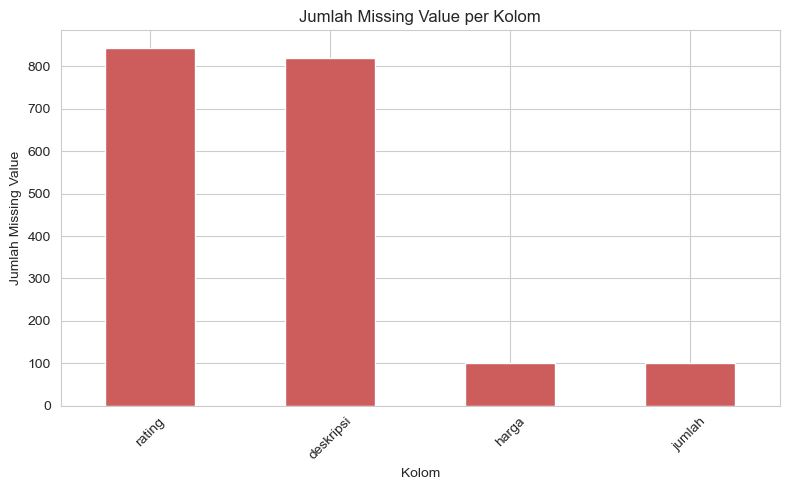

In [7]:
# Visualisasikan missing value menggunakan bar chart
plt.figure(figsize=(8,5))
missing_value[missing_value > 0].sort_values(ascending=False).plot(kind='bar', color='indianred')
plt.title('Jumlah Missing Value per Kolom')
plt.xlabel('Kolom')
plt.ylabel('Jumlah Missing Value')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Data Cleaning (Menangani Missing Value)

In [8]:
# Mengisi missing value pada kolom numerik (harga, jumlah, rating) dengan mean
kolom_numerik = ['harga', 'jumlah', 'rating']
for kolom in kolom_numerik:
    df[kolom] = df[kolom].fillna(df[kolom].mean())

df[kolom_numerik].isnull().sum()

harga     0
jumlah    0
rating    0
dtype: int64

In [9]:
# Mengisi missing value pada kolom kategorikal (kategori) dengan modus
kolom_kategorikal = ['kategori']
for kolom in kolom_kategorikal:
    df[kolom] = df[kolom].fillna(df[kolom].mode()[0])

df[kolom_kategorikal].isnull().sum()

kategori    0
dtype: int64

In [10]:
# Mengganti missing value pada kolom deskripsi dengan string "tidak ada deskripsi"
df['deskripsi'] = df['deskripsi'].fillna('tidak ada deskripsi')

# Cek kembali apakah masih ada missing value di seluruh dataset
df.isnull().sum()

id                   0
nama                 0
kategori             0
harga                0
jumlah               0
rating               0
tanggal_transaksi    0
deskripsi            0
dtype: int64

## 4. Data Integration (Menambahkan Kolom Baru)

In [11]:
# Membuat kolom total_harga = harga * jumlah
df['total_harga'] = df['harga'] * df['jumlah']

df[['harga', 'jumlah', 'total_harga']].head(10)

,harga,jumlah,total_harga
0,3443468.0,18.0,61982424.0
1,1625270.0,14.0,22753780.0
2,1099100.0,1.0,1099100.0
3,2217312.0,10.0,22173120.0
4,4685195.0,10.0,46851950.0
5,578933.0,10.0,5789330.0
6,394903.0,2.0,789806.0
7,4079604.0,8.0,32636832.0
8,791608.0,1.0,791608.0
9,1176026.0,1.0,1176026.0


In [12]:
# Mengubah kolom tanggal_transaksi menjadi tipe datetime
df['tanggal_transaksi'] = pd.to_datetime(df['tanggal_transaksi'])

# Mengambil bulan dari kolom tanggal_transaksi menjadi kolom bulan_transaksi
df['bulan_transaksi'] = df['tanggal_transaksi'].dt.month

df[['tanggal_transaksi', 'bulan_transaksi']].head(10)

,tanggal_transaksi,bulan_transaksi
0,2023-01-01 00:00:00,1
1,2023-01-01 01:00:00,1
2,2023-01-01 02:00:00,1
3,2023-01-01 03:00:00,1
4,2023-01-01 04:00:00,1
5,2023-01-01 05:00:00,1
6,2023-01-01 06:00:00,1
7,2023-01-01 07:00:00,1
8,2023-01-01 08:00:00,1
9,2023-01-01 09:00:00,1


## 5. Data Transformation

In [13]:
# Normalisasi kolom harga dan jumlah menggunakan MinMaxScaler
scaler = MinMaxScaler()
df[['harga_norm', 'jumlah_norm']] = scaler.fit_transform(df[['harga', 'jumlah']])

df[['harga', 'harga_norm', 'jumlah', 'jumlah_norm']].head(10)

,harga,harga_norm,jumlah,jumlah_norm
0,3443468.0,0.688161,18.0,0.944444
1,1625270.0,0.323741,14.0,0.722222
2,1099100.0,0.218280,1.0,0.000000
3,2217312.0,0.442403,10.0,0.500000
4,4685195.0,0.937040,10.0,0.500000
5,578933.0,0.114024,10.0,0.500000
6,394903.0,0.077139,2.0,0.055556
7,4079604.0,0.815662,8.0,0.388889
8,791608.0,0.156650,1.0,0.000000
9,1176026.0,0.233699,1.0,0.000000


In [14]:
# Membuat kolom rating_label berdasarkan nilai rating
def labelkan_rating(rating):
    if rating <= 2:
        return 'buruk'
    elif rating == 3:
        return 'cukup'
    else:
        return 'baik'

df['rating_label'] = df['rating'].apply(labelkan_rating)

df[['rating', 'rating_label']].head(10)

,rating,rating_label
0,2.000000,buruk
1,5.000000,baik
2,5.000000,baik
3,2.965119,baik
4,4.000000,baik
5,4.000000,baik
6,4.000000,baik
7,5.000000,baik
8,2.965119,baik
9,4.000000,baik


## 6. Data Reduction (PCA)

In [15]:
# Melakukan PCA pada kolom numerik (harga, jumlah, rating)
fitur_pca = df[['harga', 'jumlah', 'rating']]

pca = PCA(n_components=2)  # Ambil 2 principal components
hasil_pca = pca.fit_transform(fitur_pca)

# Menyimpan hasil PCA ke dalam dataframe
df['PC1'] = hasil_pca[:, 0]
df['PC2'] = hasil_pca[:, 1]

df[['harga', 'jumlah', 'rating', 'PC1', 'PC2']].head(10)

,harga,jumlah,rating,PC1,PC2
0,3443468.0,18.0,2.000000,9.277655e+05,7.792712
1,1625270.0,14.0,5.000000,-8.904325e+05,3.835481
2,1099100.0,1.0,5.000000,-1.416602e+06,-9.150327
3,2217312.0,10.0,2.965119,-2.983905e+05,-0.176253
4,4685195.0,10.0,4.000000,2.169493e+06,-0.244819
5,578933.0,10.0,4.000000,-1.936769e+06,-0.134282
6,394903.0,2.0,4.000000,-2.120799e+06,-8.129312
7,4079604.0,8.0,5.000000,1.563902e+06,-2.230574
8,791608.0,1.0,2.965119,-1.724094e+06,-9.137855
9,1176026.0,1.0,4.000000,-1.339676e+06,-9.150337


## 7. Text Processing - Tokenizing & Filtering

In [17]:
# Menyiapkan daftar stopwords Bahasa Indonesia menggunakan nltk
# nltk tidak punya stopwords Bahasa Indonesia bawaan, sehingga kita definisikan daftar stopwords sendiri
stopwords_id = set([
    'yang', 'di', 'ke', 'dari', 'dan', 'atau', 'ini', 'itu', 'dengan',
    'untuk', 'pada', 'adalah', 'saya', 'kami', 'kita', 'dia', 'mereka',
    'akan', 'sudah', 'belum', 'juga', 'tidak', 'ada', 'karena', 'jadi',
    'sangat', 'nya', 'agar', 'saat', 'oleh', 'para', 'namun', 'serta'
])

print("Jumlah stopwords:", len(stopwords_id))

Jumlah stopwords: 33


In [18]:
# Fungsi tokenizing menggunakan nltk word_tokenize
def tokenize_teks(teks):
    return word_tokenize(teks.lower())

# Fungsi filtering: hapus stopwords, tanda baca, dan token dengan panjang < 3 karakter
def filter_token(tokens):
    hasil = []
    for token in tokens:
        if token in string.punctuation:
            continue
        if token in stopwords_id:
            continue
        if len(token) < 3:
            continue
        hasil.append(token)
    return hasil

# Menerapkan tokenizing dan filtering pada kolom deskripsi
df['tokens'] = df['deskripsi'].apply(lambda x: filter_token(tokenize_teks(x)))

# Menampilkan hasil ulasan (tokens)
df['tokens'].head(10)

0                          [puas]
1             [pengiriman, cepat]
2                          [puas]
3    [produk, bagus, berkualitas]
4         [harga, terlalu, mahal]
5                          [puas]
6                          [puas]
7                     [deskripsi]
8         [harga, terlalu, mahal]
9                     [deskripsi]
Name: tokens, dtype: object

## 8. Visualisasi Data

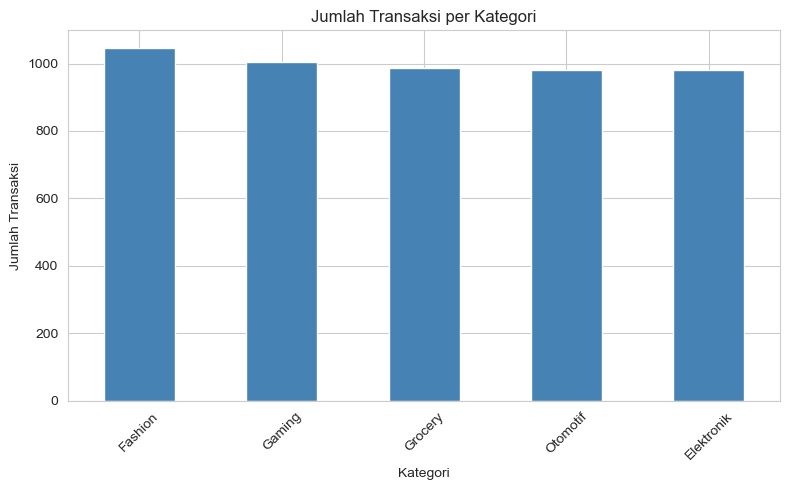

In [19]:
# Bar chart jumlah transaksi per kategori
plt.figure(figsize=(8,5))
df['kategori'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Jumlah Transaksi per Kategori')
plt.xlabel('Kategori')
plt.ylabel('Jumlah Transaksi')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

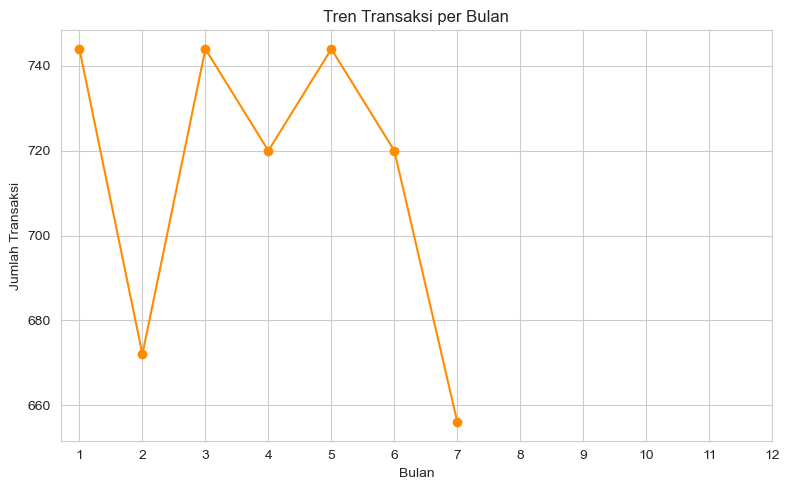

In [20]:
# Line chart tren transaksi per bulan
transaksi_per_bulan = df.groupby('bulan_transaksi').size()

plt.figure(figsize=(8,5))
transaksi_per_bulan.plot(kind='line', marker='o', color='darkorange')
plt.title('Tren Transaksi per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Transaksi')
plt.xticks(range(1,13))
plt.tight_layout()
plt.show()

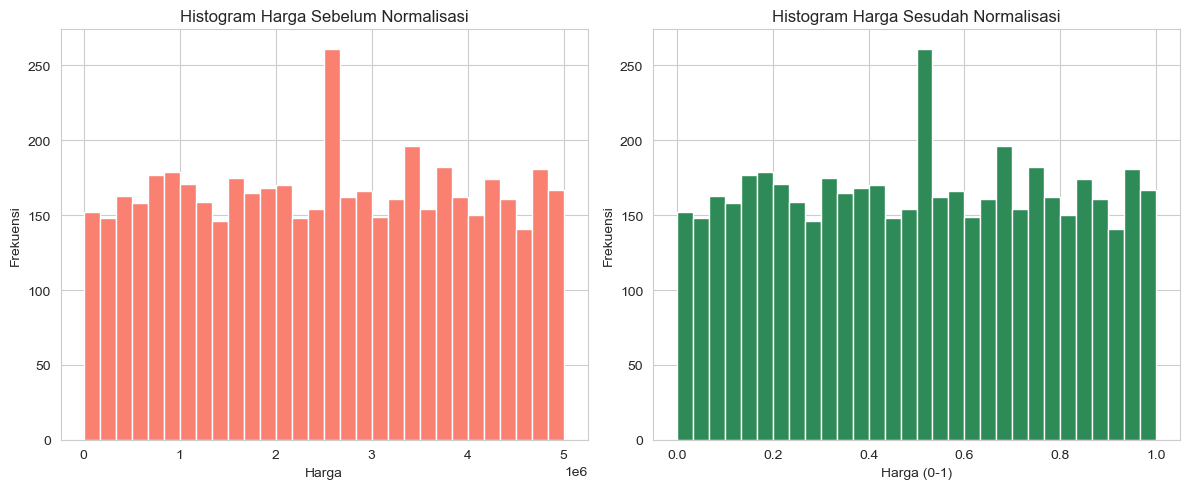

In [21]:
# Histogram harga sebelum dan sesudah normalisasi
fig, axes = plt.subplots(1, 2, figsize=(12,5))

axes[0].hist(df['harga'], bins=30, color='salmon')
axes[0].set_title('Histogram Harga Sebelum Normalisasi')
axes[0].set_xlabel('Harga')
axes[0].set_ylabel('Frekuensi')

axes[1].hist(df['harga_norm'], bins=30, color='seagreen')
axes[1].set_title('Histogram Harga Sesudah Normalisasi')
axes[1].set_xlabel('Harga (0-1)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

In [22]:
# Menampilkan kata yang paling sering muncul dalam deskripsi produk
semua_token = [token for daftar in df['tokens'] for token in daftar]
frekuensi_kata = Counter(semua_token)

kata_terbanyak = frekuensi_kata.most_common(15)
print("15 kata yang paling sering muncul:")
for kata, jumlah in kata_terbanyak:
    print(f"{kata}: {jumlah}")

15 kata yang paling sering muncul:
puas: 902
harga: 872
terlalu: 872
mahal: 872
kemasan: 829
kurang: 829
rapi: 829
deskripsi: 819
pengiriman: 797
cepat: 797
produk: 781
bagus: 781
berkualitas: 781


In [24]:
# Menampilkan bigram (pasangan kata) yang sering muncul, contoh: "harga mahal", "pengiriman cepat"
def buat_bigram(tokens):
    return [(tokens[i], tokens[i+1]) for i in range(len(tokens)-1)]

semua_bigram = []
for daftar_token in df['tokens']:
    semua_bigram.extend(buat_bigram(daftar_token))

frekuensi_bigram = Counter(semua_bigram)
bigram_terbanyak = frekuensi_bigram.most_common(10)

print("10 bigram (pasangan kata) yang paling sering muncul:")
for pasangan, jumlah in bigram_terbanyak:
    print(f"{pasangan[0]} {pasangan[1]}: {jumlah}")

10 bigram (pasangan kata) yang paling sering muncul:
harga terlalu: 872
terlalu mahal: 872
kemasan kurang: 829
kurang rapi: 829
pengiriman cepat: 797
produk bagus: 781
bagus berkualitas: 781
